# What does a galaxy classifier actually look at? Explaining a five-band CNN in astronomical terms

For ASTRO 416 I trained a neural network to sort galaxies as spiral or elliptical using Galaxy Zoo labels and SDSS images. In project 1 for this course I tested whether saliency maps can catch a classifier that cheats, and found that pixel-level maps can look convincing without reflecting what the model uses.

This project goes back to the original question, whether a CNN can classify spiral and elliptical galaxies, and asks what features it uses to do it. Instead of explaining the model pixel by pixel, I explain it in terms an astronomer would use:

1. **Bands.** SDSS images every galaxy in five bands, from near-ultraviolet (u) through green (g), red (r) and near-infrared (i, z). The model gets each band as a separate input channel, so I can measure exactly how much each band contributes.
2. **Regions.** Each galaxy is split into a core, the main body, the outskirts, and the surrounding background, using its own measured radii.
3. **Concepts.** Galaxy Zoo 2 volunteers answered detailed questions about each galaxy: does it have a bar, spiral arms, a prominent central bulge, is it edge-on? Those answers define concepts I can test the model against.
4. **Physical checks.** Do the explanations line up with other measurements of the galaxies, like how much of a galaxy's light comes from its central bulge?
5. **Less certain galaxies.** How does the model handle galaxies volunteers agreed on less?
6. **Checks on the explanations.** Do the Shapley values change when the model's weights are randomized, and does removing the parts with the largest values hurt the prediction most?

Before any of that, a simple classifier on SDSS catalog values (colors and light-profile shape) sets a baseline, so the explanations can show what the CNN adds beyond those numbers.

The band and region explanations are exact Shapley values, computed from the model's actual outputs, so they don't depend on gradients or on how a heatmap happens to look.

The data pipeline and training are in `scripts/` (see the README), and this notebook runs the analysis.

In [1]:
import sys
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

sys.path.insert(0, "src")
from galaxy_bands import config as C, data as D, experiments as E, model as M, train as T

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
C.FIGURES.mkdir(exist_ok=True)

device = T.get_device()
T.seed_everything(C.SEED)
data = D.GalaxyData(device)
models = {m: M.load(C.MODELS / f"{m}.pt", device) for m in T.MODES}
model = models["band_dropout"]
df = data.df
print(device, tuple(data.x.shape))

mps (7052, 5, 128, 128)


In [2]:
BAND_COLORS = dict(zip(C.BANDS, ["#6a3d9a", "#1f78b4", "#33a02c", "#e6a100", "#b2182b"]))
CLASS_COLORS = {"spiral": "#3b6fb6", "elliptical": "#c0504d"}
REGION_SHORT = ["core", "body", "outskirts", "background"]

def cached(name, fn):
    path = C.RESULTS / f"{name}.csv"
    if path.exists():
        return pd.read_csv(path)
    out = fn()
    out.to_csv(path, index=False)
    return out

def savefig(fig, name):
    fig.savefig(C.FIGURES / f"{name}.png", dpi=200, bbox_inches="tight")

## The data

The sample is made up of confident spiral and elliptical galaxies from Galaxy Zoo 1: at least 30 votes, and more than 85% of the debiased vote for one type. I kept only galaxies that are also in the Galaxy Zoo 2 catalog (Hart et al. 2016 version), so every galaxy also has the detailed Galaxy Zoo 2 answers. In Galaxy Zoo 1 the spiral category combines clockwise, anticlockwise, and edge-on votes, so "spiral" here means disk galaxies in general.

A separate set of galaxies comes from Galaxy Builder, where volunteers built models of spiral galaxies out of a disk, central bulge, bar, and spiral arms. Those galaxies are never used for training; they're only used to check the explanations against the fitted components.

For every galaxy I downloaded the calibrated SDSS frames in all five bands and resampled each band onto the same 128×128 grid, 4 × R90 across (R90 is the radius containing 90% of the galaxy's Petrosian flux in the r band). Each band is then stretched with an arcsinh in units of that band's own background noise. Galaxies too close to the edge of an SDSS frame to be fully covered in every band were dropped.

In [3]:
print(df.groupby(["split", "label"]).size().unstack(fill_value=0))
noise = json.loads((C.RESULTS / "band_noise.json").read_text())
print("background noise per band (nanomaggies per pixel, median over training cutouts):",
      dict(zip(C.BANDS, np.round(noise, 4))))

label           elliptical  spiral
split                             
galaxy_builder           0     191
moderate               496     495
test                   440     439
train                 2066    2048
val                    439     438
background noise per band (nanomaggies per pixel, median over training cutouts): {'u': np.float64(0.0281), 'g': np.float64(0.0111), 'r': np.float64(0.0176), 'i': np.float64(0.0294), 'z': np.float64(0.1102)}


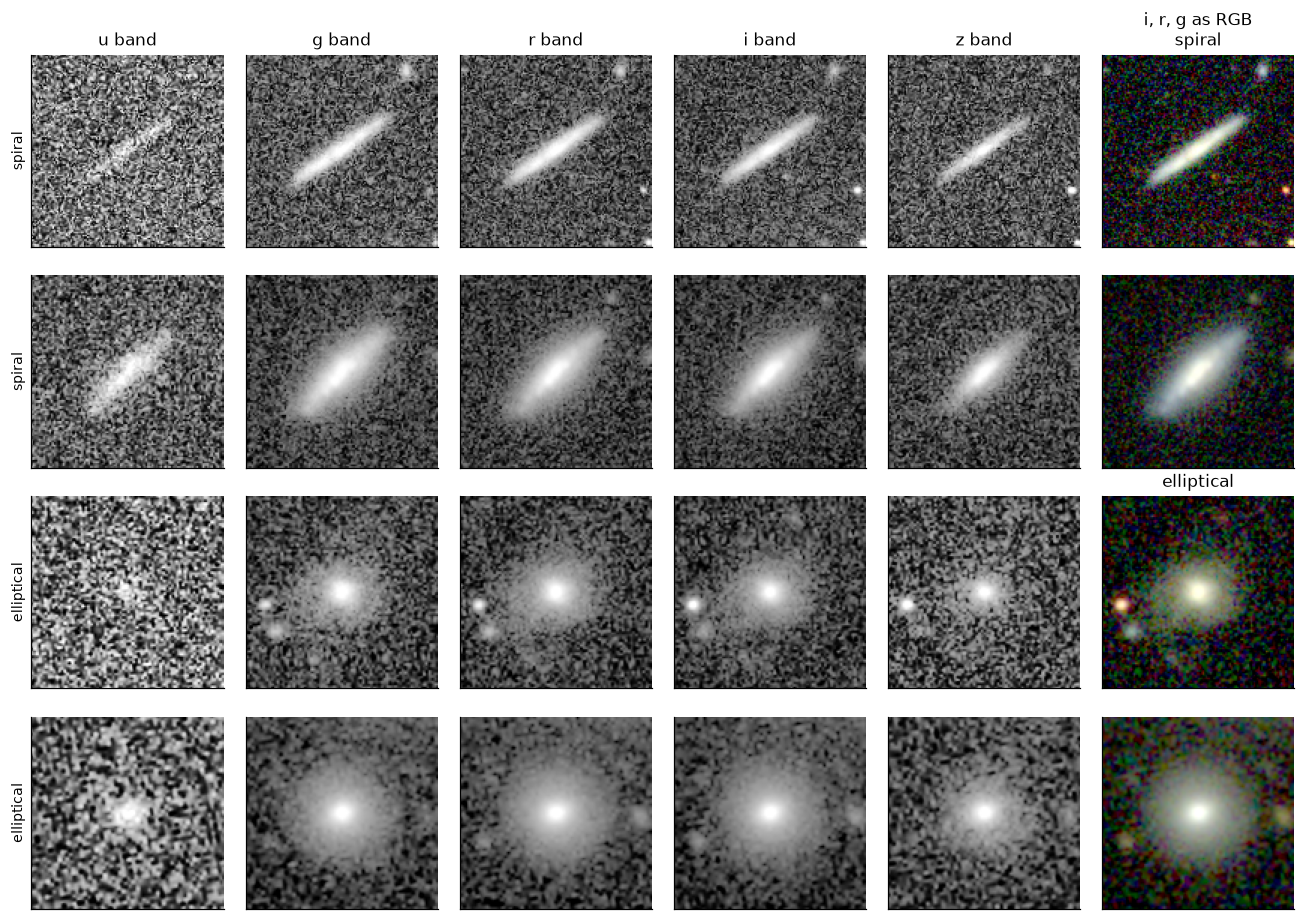

In [4]:
fig, axes = plt.subplots(4, 6, figsize=(12, 8.4))
rng = np.random.default_rng(1)
picks = [rng.choice(np.where((df.label == c) & (df.split == "test"))[0]) for c in ["spiral", "spiral", "elliptical", "elliptical"]]
for r, i in enumerate(picks):
    cube = data.x[i].cpu().numpy()
    for c, b in enumerate(C.BANDS):
        axes[r, c].imshow(cube[c], cmap="gray", vmin=np.percentile(cube[c], 1), vmax=np.percentile(cube[c], 99.8))
        if r == 0:
            axes[r, c].set_title(f"{b} band")
    rgb = np.stack([cube[3], cube[2], cube[1]], -1)
    rgb = np.clip(rgb / np.percentile(rgb, 99.8), 0, 1)
    axes[r, 5].imshow(rgb)
    axes[r, 5].set_title(df.label[i] if r in (0, 2) else "")
    axes[r, 0].set_ylabel(df.label[i])
for a in axes.flat:
    a.set_xticks([]); a.set_yticks([])
axes[0, 5].set_title("i, r, g as RGB\nspiral")
fig.tight_layout()
savefig(fig, "five_band_examples")

Galaxies are much fainter in u than in the other bands. Inside the half-light radius the median signal-to-noise of a training galaxy is about 56 in u, against 270 to 860 in g, r, i, and z, so faint structure mostly disappears in u. The z band has the most background noise per pixel, but galaxies are bright enough there that it matters less.

The two classes also differ in color. The plot below uses SDSS's extinction-corrected model magnitudes.

            u_minus_r  g_minus_r      z  fracDeV_r
label                                             
elliptical      2.863      0.934  0.089      1.000
spiral          2.106      0.686  0.066      0.257


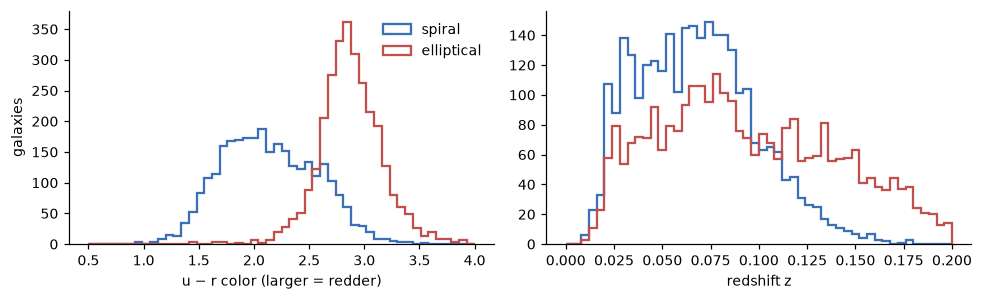

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8))
for lab in C.CLASSES:
    d = df[(df.label == lab) & (df.split.isin(["train", "val", "test"]))]
    axes[0].hist(d.u_minus_r, bins=50, range=(0.5, 4), histtype="step", lw=1.5, color=CLASS_COLORS[lab], label=lab)
    axes[1].hist(d.z.dropna(), bins=50, range=(0, 0.2), histtype="step", lw=1.5, color=CLASS_COLORS[lab], label=lab)
axes[0].set(xlabel="u − r color (larger = redder)", ylabel="galaxies")
axes[1].set(xlabel="redshift z")
axes[0].legend(frameon=False)
fig.tight_layout()
savefig(fig, "color_redshift")
print(df[df.split.isin(["train", "val", "test"])].groupby("label")[["u_minus_r", "g_minus_r", "z", "fracDeV_r"]].median().round(3))

After dropping 99 galaxies whose cutouts ran off the edge of an SDSS frame in at least one band, 6,061 galaxies remain: 4,114 for training, 877 for validation, 879 for testing, and 191 from Galaxy Builder. The classes are balanced in every split. A further 991 galaxies with less volunteer agreement are used as an extra test set in section 6.

The two classes differ in ways besides shape. Elliptical galaxies are redder (median u − r of 2.86 against 2.11 for spiral galaxies) and sit at slightly higher redshift (median z of 0.089 against 0.066). Their light profiles also look different: SDSS's fracDeV_r, the weight given to the de Vaucouleurs (elliptical-like) profile when the r-band light is fit as a mix of that and an exponential (disk-like) profile, has a median of 1.00 for elliptical galaxies and 0.26 for spiral galaxies. Every cutout is scaled to the galaxy's own size, so apparent size is mostly removed as a clue, but color is not, and that is one of the things the explanations below check for.

## Training

The CNN is the same architecture as in project 1 (four convolutional blocks, global average pooling, dropout, a linear layer), with five input channels instead of three, and it reuses the hyperparameters tuned with Optuna in project 1. Training uses random 90° rotations and flips, up to 150 epochs with early stopping on validation loss (patience 25).

I trained two versions. The main one uses **band dropout**: during training each band is blanked with probability 0.15 (always keeping at least one). The experiments below measure a band's importance by removing it, and band dropout means the model has seen images with missing bands before, so its response to a removed band is a response it learned rather than a reaction to an input unlike anything in training. The second version, trained without band dropout, is used at the end to check that the conclusions don't depend on this choice.

band_dropout  150 epochs, best epoch 150, val acc 1.000
plain         74 epochs, best epoch 49, val acc 1.000


,model,split,acc,auc,nll
0,band_dropout,test,0.997,1.000,0.014
1,band_dropout,galaxy_builder,0.984,NaN,0.019
2,band_dropout,moderate,0.980,0.998,0.068
3,plain,test,0.995,1.000,0.014
4,plain,galaxy_builder,0.979,NaN,0.025
5,plain,moderate,0.974,0.996,0.078


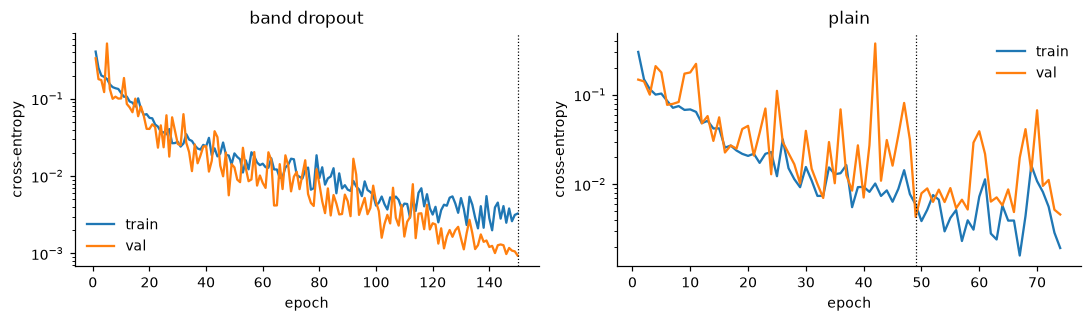

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, mode in zip(axes, T.MODES):
    h = pd.read_csv(C.RESULTS / f"history_{mode}.csv")
    ax.plot(h.epoch, h.train_loss, label="train")
    ax.plot(h.epoch, h.val_loss, label="val")
    ax.axvline(h.epoch[h.val_loss.idxmin()], c="k", ls=":", lw=0.8)
    ax.set(title=mode.replace("_", " "), xlabel="epoch", ylabel="cross-entropy", yscale="log")
    ax.legend(frameon=False)
fig.tight_layout()
savefig(fig, "learning_curves")
for mode in T.MODES:
    h = pd.read_csv(C.RESULTS / f"history_{mode}.csv")
    print(f"{mode:13s} {len(h)} epochs, best epoch {h.epoch[h.val_loss.idxmin()]}, val acc {h.val_acc[h.val_loss.idxmin()]:.3f}")
pd.read_csv(C.RESULTS / "test_metrics.csv").round(3)

In [7]:
ablation = cached("band_ablation", lambda: E.band_ablation(model, data, "test"))
ablation.round(3)

,bands,acc,auc,nll
0,all five,0.997,1.000,0.014
1,u only,0.722,0.750,0.668
2,without u,0.995,1.000,0.013
3,g only,0.989,0.999,0.033
4,without g,0.994,1.000,0.016
5,r only,0.983,0.999,0.044
6,without r,0.995,1.000,0.014
7,i only,0.966,0.996,0.102
8,without i,0.997,1.000,0.010
9,z only,0.943,0.988,0.167


Both models do very well on the test set: 99.7% accuracy with band dropout and 99.5% without, with 3 and 4 mistakes out of 879 galaxies. The band dropout model kept improving slowly until the last epoch (150), when the learning rate had almost reached zero. The plain model stopped at epoch 74 and its best epoch was 49. On the 191 Galaxy Builder spiral galaxies, which were kept out of training, the main model calls 98.4% spiral.

Accuracy this high on confident Galaxy Zoo galaxies is not surprising, and it says nothing on its own about how the model decides. The band ablation table is the first hint. With any single band removed, accuracy stays at 99.4% or higher, so no one band is essential. More interesting, the model still gets 98.9% right from the g band alone and 98.3% from r alone. A single band carries no color information, so the model must be able to separate the classes from the light distribution alone. The u band is the exception: on its own it gives 72%, which fits how faint galaxies are in u.

### Baseline: a classifier on catalog values

SDSS already measures each galaxy's colors and the shape of its light profile. A logistic regression on those numbers, trained on the same training galaxies, shows how far they get without looking at the images. I used two colors (u − r and g − r) and two structure measurements (fracDeV_r and the concentration R90/R50), alone and together.

In [8]:
baseline, catalog_preds = E.catalog_baseline(df)
cnn = pd.read_csv(C.RESULTS / "test_metrics.csv").query("model == 'band_dropout' and split != 'galaxy_builder'")
table = baseline.pivot(index="features", columns="split", values="acc")
table.loc["CNN (five-band images)"] = cnn.set_index("split").acc
print(table.round(3))

# where the extra accuracy comes from: test galaxies the catalog model gets wrong
regions_test = cached("region_shapley_test", lambda: E.region_shapley(model, data, "test"))
cmp = regions_test.merge(catalog_preds, on="OBJID").merge(df[["OBJID", "y"]], on="OBJID")
cmp["catalog_right"] = cmp.catalog_pred == cmp.y
wrong = ~cmp.catalog_right
print(f"\ntest galaxies the catalog model gets wrong: {wrong.sum()}, CNN accuracy on them: {(cmp.pred == cmp.label)[wrong].mean():.3f}")
print(cmp[wrong].label.value_counts().to_dict())
by = cmp.groupby(["label", "catalog_right"])[[f"phi_region{r}" for r in range(D.N_REGIONS)]].mean()
by.columns = REGION_SHORT
print("\nmean region Shapley values (log-odds toward the predicted class)")
by.round(2)


split                                moderate   test
features                                            
color and structure                     0.830  0.919
color only (u − r, g − r)               0.767  0.863
structure only (fracDeV_r, R90/R50)     0.825  0.906
CNN (five-band images)                  0.980  0.997

test galaxies the catalog model gets wrong: 71, CNN accuracy on them: 0.972
{'spiral': 46, 'elliptical': 25}

mean region Shapley values (log-odds toward the predicted class)


core   body  outskirts  background
label      catalog_right                                    
elliptical False          4.73  -0.06       2.78        0.90
           True           6.65   0.41       3.41        1.61
spiral     False         -0.74  10.19       3.08        0.88
           True           2.71   9.11       2.28        0.64

The catalog values go a long way. Color alone gets 86.3% of the test set right, structure alone 90.6%, and both together 91.9%. Both kinds of information really do separate the two classes. The CNN gets 99.7%, so the images add about 8 points beyond what these four numbers capture. The gap is larger for the galaxies volunteers agreed on less: 83.0% for the catalog model against 98.0% for the CNN.

The 71 test galaxies the catalog model gets wrong show where the extra accuracy comes from, and the CNN gets 97% of them right. Most of them (46) are spiral galaxies. For those spiral galaxies, the core region on average points toward elliptical (−0.74 log-odds), while the body region, where most of the disk's light usually is, gives even more evidence for spiral than usual (10.2 against 9.1). These look like spiral galaxies whose overall colors and light profiles resemble an elliptical's, for example because of a large central bulge. The CNN classifies them by the disk, which a few summary numbers can't describe. For the 25 elliptical galaxies the catalog model misses, the CNN uses the same core and outskirts pattern as for other elliptical galaxies, just with less evidence overall.

## 1. Which bands does the model use?

For every test galaxy I computed the exact Shapley value of each band. A band's Shapley value is its average contribution to the model's log-odds for the class it predicted, averaged over every possible combination of the other bands being present or removed. With five bands that's 32 combinations per galaxy, few enough to compute exactly, so there's no sampling noise. The five values add up to the difference between the model's output on the full image and on a blank one.

,spiral,elliptical,share (spiral),share (elliptical)
u,0.399,0.194,0.043,0.043
g,4.524,3.065,0.304,0.252
r,4.100,3.401,0.272,0.279
i,3.229,2.943,0.218,0.240
z,2.346,2.264,0.163,0.186


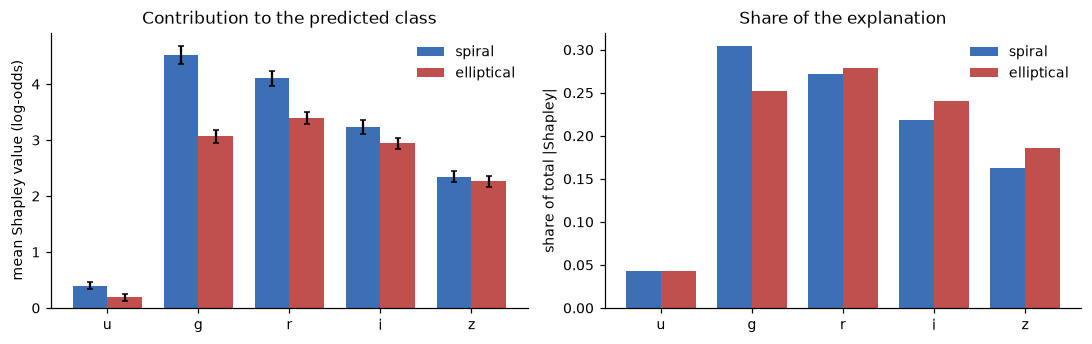

In [9]:
bands = cached("band_shapley_test", lambda: E.band_shapley(model, data, "test"))
phi = bands[[f"phi_{b}" for b in C.BANDS]].values
share = E.shares(phi)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
w = 0.38
for k, lab in enumerate(C.CLASSES):
    m = (bands.label == lab).values
    axes[0].bar(np.arange(5) + (k - 0.5) * w, phi[m].mean(0), w, yerr=1.96 * phi[m].std(0) / np.sqrt(m.sum()),
                capsize=2, color=CLASS_COLORS[lab], label=lab)
    axes[1].bar(np.arange(5) + (k - 0.5) * w, share[m].mean(0), w, color=CLASS_COLORS[lab], label=lab)
for ax in axes:
    ax.set_xticks(range(5), C.BANDS)
    ax.legend(frameon=False)
axes[0].axhline(0, c="k", lw=0.5)
axes[0].set(ylabel="mean Shapley value (log-odds)", title="Contribution to the predicted class")
axes[1].set(ylabel="share of total |Shapley|", title="Share of the explanation")
fig.tight_layout()
savefig(fig, "band_shapley")

summary = pd.DataFrame({lab: phi[(bands.label == lab).values].mean(0) for lab in C.CLASSES}, index=C.BANDS)
summary["share (spiral)"] = share[(bands.label == "spiral").values].mean(0)
summary["share (elliptical)"] = share[(bands.label == "elliptical").values].mean(0)
summary.round(3)

Spiral galaxies are bluer than elliptical galaxies, so a natural question is whether the bluer bands matter more for bluer galaxies. Within each class, I compare each galaxy's u + g share of the explanation with its u − r color.

,class,spearman rho (u−r vs u+g share),p,n
0,spiral,-0.1547,0.0012,439
1,elliptical,-0.1146,0.0162,440


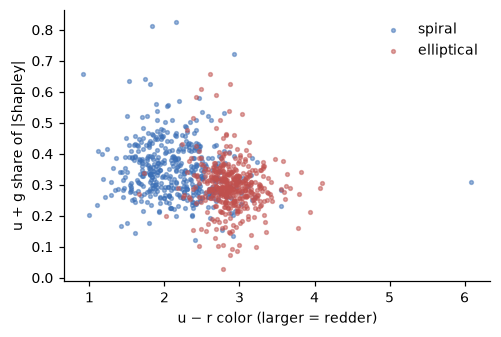

In [10]:
tdf = df.set_index("OBJID").loc[bands.OBJID].reset_index()
blue_share = share[:, 0] + share[:, 1]
rows = []
for lab in C.CLASSES:
    m = (bands.label == lab).values
    rho, p, n = E.correlate(tdf.u_minus_r.values[m], blue_share[m])
    rows.append({"class": lab, "spearman rho (u−r vs u+g share)": rho, "p": p, "n": n})
fig, ax = plt.subplots(figsize=(5, 3.2))
for lab in C.CLASSES:
    m = (bands.label == lab).values
    ax.scatter(tdf.u_minus_r.values[m], blue_share[m], s=6, alpha=0.5, color=CLASS_COLORS[lab], label=lab)
ax.set(xlabel="u − r color (larger = redder)", ylabel="u + g share of |Shapley|")
ax.legend(frameon=False)
savefig(fig, "blue_share_vs_color")
pd.DataFrame(rows).round(4)

The model's total evidence for its prediction (the log-odds with all five bands) has a median of about 13 to 14, and with every band removed it is close to zero, so nearly all of the evidence is shared out among the bands. Most of it comes from g, r, and i. The u band gets about 4% of the explanation for both classes, and z gets 16 to 19%.

The two classes use the bands a little differently. Spiral galaxies get more of their explanation from g (30%, against 25% for elliptical galaxies), and elliptical galaxies get slightly more from r, i, and z. That is the direction expected from color, since spiral galaxies have more young, blue stars, but the difference is small. Within each class, bluer galaxies get a slightly larger u + g share (Spearman ρ = −0.15 for spiral galaxies and −0.11 for elliptical galaxies between u − r and the u + g share). Both correlations are weak, though both are statistically significant (p = 0.001 and 0.016). So color plays some part, but the bands mostly act as five noisy copies of the same picture, weighted by how clearly each one shows the galaxy.

## 2. Which parts of the galaxy does the model use?

Each galaxy is split into four regions using its own SDSS radii: the **core** (inside R50, the radius containing half the light), the **body** (R50 to R90), the **outskirts** (R90 to 1.5 R90) and the **background** beyond that. With four regions, exact Shapley values need only 16 combinations. Removing a region means blanking it in all five bands.

,spiral,elliptical
core,2.349,6.539
body,9.220,0.380
outskirts,2.365,3.377
background,0.664,1.571


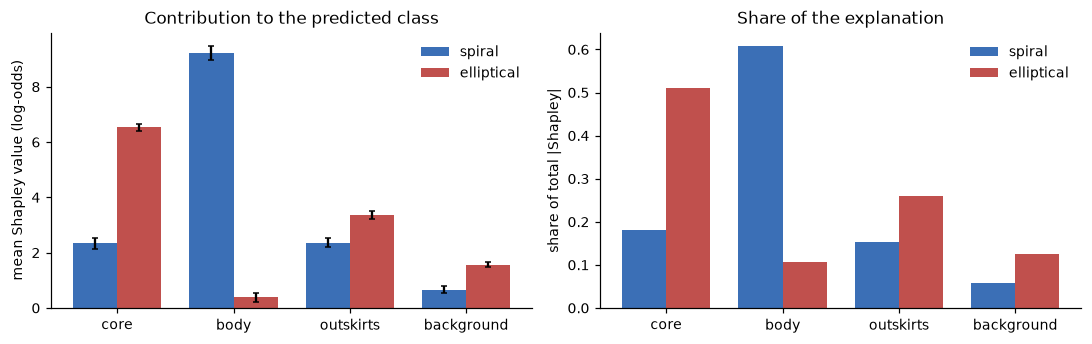

In [11]:
regions = cached("region_shapley_test", lambda: E.region_shapley(model, data, "test"))
rphi = regions[[f"phi_region{r}" for r in range(D.N_REGIONS)]].values
rshare = E.shares(rphi)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
w = 0.38
for k, lab in enumerate(C.CLASSES):
    m = (regions.label == lab).values
    axes[0].bar(np.arange(4) + (k - 0.5) * w, rphi[m].mean(0), w, yerr=1.96 * rphi[m].std(0) / np.sqrt(m.sum()),
                capsize=2, color=CLASS_COLORS[lab], label=lab)
    axes[1].bar(np.arange(4) + (k - 0.5) * w, rshare[m].mean(0), w, color=CLASS_COLORS[lab], label=lab)
for ax in axes:
    ax.set_xticks(range(4), REGION_SHORT)
    ax.legend(frameon=False)
axes[0].axhline(0, c="k", lw=0.5)
axes[0].set(ylabel="mean Shapley value (log-odds)", title="Contribution to the predicted class")
axes[1].set(ylabel="share of total |Shapley|", title="Share of the explanation")
fig.tight_layout()
savefig(fig, "region_shapley")
pd.DataFrame({lab: rphi[(regions.label == lab).values].mean(0) for lab in C.CLASSES}, index=REGION_SHORT).round(3)

Combining bands and regions gives 20 groups, too many for exact Shapley values, so for 200 test galaxies (100 per class) I used KernelSHAP, which estimates Shapley values from 2,000 random combinations per galaxy.

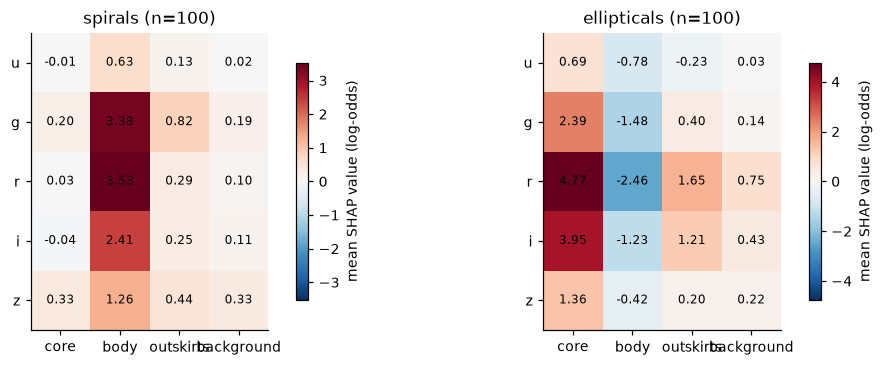

In [12]:
br = cached("band_region_shap_test", lambda: E.band_region_shap(model, data, "test", n=200))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, lab in zip(axes, C.CLASSES):
    g = br[br.label == lab]
    grid = np.array([[g[f"{b}_region{r}"].mean() for r in range(D.N_REGIONS)] for b in C.BANDS])
    lim = np.abs(grid).max()
    im = ax.imshow(grid, cmap="RdBu_r", vmin=-lim, vmax=lim)
    for (bi, ri), v in np.ndenumerate(grid):
        ax.text(ri, bi, f"{v:.2f}", ha="center", va="center", fontsize=8)
    ax.set_xticks(range(4), REGION_SHORT)
    ax.set_yticks(range(5), C.BANDS)
    ax.set_title(f"{lab}s (n={len(g)})")
    fig.colorbar(im, ax=ax, shrink=0.8, label="mean SHAP value (log-odds)")
fig.tight_layout()
savefig(fig, "band_region_shap")

The regions show the clearest difference between the classes. For spiral galaxies, most of the evidence comes from the body of the galaxy, between the half-light radius and R90 (9.2 out of 14.6 log-odds on average). That is where most of a disk's light, including the arms, usually is. The regions are based on how much light they enclose, not on separate parts of the galaxy, so the body only roughly matches the disk and the core only roughly matches the central bulge. For elliptical galaxies, most comes from the core (6.5) and the outskirts (3.4), and the body adds almost nothing (0.4). In both classes the background beyond 1.5 R90 contributes a little (0.7 for spiral galaxies and 1.6 for elliptical galaxies). Some of that is probably real galaxy light, since elliptical light profiles fall off slowly and can extend past 1.5 R90, but neighboring objects in the background could also play a part.

The band × region KernelSHAP results agree for spiral galaxies: the body in g and r carries most of the evidence. For elliptical galaxies, they put even more weight on the core, mostly in r and i, and give the body negative values in every band. That disagrees with the exact region values above. The two calculations explain different things. Splitting by band creates inputs like "body light in r only, with no core in r", which look nothing like a real galaxy, and KernelSHAP is also only an estimate. I only take the strongest patterns from this figure: the spiral evidence sits in the disk, mostly in g and r, and the elliptical evidence sits in the core, mostly in r and i.

## 3. Does the model respond to the morphology concepts volunteers see?

Testing with Concept Activation Vectors (TCAV) asks whether moving the model's internal activations toward a human-defined concept changes its prediction. For each concept I took 100 example galaxies that Galaxy Zoo 2 volunteers agreed show it, plus 100 random galaxies without it, and trained a linear classifier to separate their activations after the third convolutional block. The classifier's direction is the concept's activation vector. The TCAV score for a class is the fraction of that class's test galaxies whose log-odds increase when the activations move in the concept's direction.

Each concept is repeated 20 times with different random galaxies, and compared with 20 random-vs-random vectors using a t-test (Bonferroni corrected). Concept examples come from the training and validation sets; scores are measured on the test set.

Galaxy Zoo 2 is a decision tree: volunteers only answer the bar, central bulge, and arm questions after saying a galaxy has features or a disk and is not edge-on. Those vote fractions are out of the volunteers who reached the question, so they can be high from one or two votes on a smooth galaxy. Each concept therefore also requires the earlier answers. In the table, "disk" means features or disk > 0.5 and "face-on disk" adds not edge-on > 0.5.

| concept | Galaxy Zoo 2 definition (debiased vote fractions) |
|---|---|
| spiral arms | face-on disk and arms > 0.9 |
| bar | face-on disk and bar > 0.5 |
| prominent bulge | face-on disk and obvious + dominant bulge > 0.7 |
| edge-on disk | disk and edge-on > 0.9 |
| round and smooth | smooth > 0.8 and completely round > 0.7 |
| tightly wound arms | face-on disk, arms > 0.8 and tight > 0.6 |
| loosely wound arms | face-on disk, arms > 0.8 and loose > 0.5 |

spiral arms           1780 galaxies, 95% labeled spiral in GZ1
bar                    882 galaxies, 93% labeled spiral in GZ1
prominent bulge        242 galaxies, 48% labeled spiral in GZ1
edge-on disk           302 galaxies, 100% labeled spiral in GZ1
round and smooth       703 galaxies, 0% labeled spiral in GZ1
tightly wound arms     609 galaxies, 93% labeled spiral in GZ1
loosely wound arms      92 galaxies, 79% labeled spiral in GZ1


.venv/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:601: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


,concept,target,mean_score,std,random_mean,p_value,n_concept_images,significant
0,bar,elliptical,0.0000,0.0000,0.6216,0.0000,882,True
1,bar,spiral,0.9753,0.0545,0.3973,0.0000,882,True
2,edge-on disk,elliptical,0.0048,0.0182,0.6216,0.0000,302,True
3,edge-on disk,spiral,0.2918,0.1324,0.3973,0.1644,302,False
4,loosely wound arms,elliptical,0.0707,0.1485,0.6216,0.0000,92,True
5,loosely wound arms,spiral,0.3632,0.2235,0.3973,0.6876,92,False
6,prominent bulge,elliptical,0.0009,0.0036,0.6216,0.0000,242,True
7,prominent bulge,spiral,0.8024,0.1806,0.3973,0.0000,242,True
8,round and smooth,elliptical,1.0000,0.0000,0.6216,0.0005,703,True
9,round and smooth,spiral,0.0054,0.0133,0.3973,0.0000,703,True


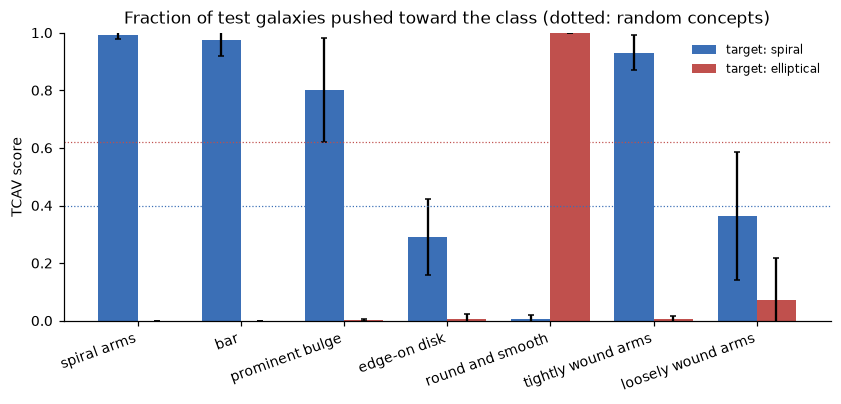

In [13]:
tc = cached("tcav_runs", lambda: E.tcav(model, data))
pool = df[df.split.isin(["train", "val"])].reset_index(drop=True)
for name, m in E.concept_sets(pool).items():
    print(f"{name:20s} {m.sum():5d} galaxies, {(pool.label[m] == 'spiral').mean():.0%} labeled spiral in GZ1")
tsum = E.tcav_summary(tc)
order = [c for c in E.concept_sets(df).keys() if c in set(tsum.concept)]
fig, ax = plt.subplots(figsize=(9, 3.4))
w = 0.38
for k, lab in enumerate(C.CLASSES):
    s = tsum[tsum.target == lab].set_index("concept").loc[order]
    ax.bar(np.arange(len(order)) + (k - 0.5) * w, s.mean_score, w, yerr=s["std"], capsize=2, color=CLASS_COLORS[lab], label=f"target: {lab}")
rand = tc[tc.concept == "random"].groupby("target").score.mean()
for lab in C.CLASSES:
    ax.axhline(rand[lab], color=CLASS_COLORS[lab], ls=":", lw=0.8)
ax.set_xticks(range(len(order)), order, rotation=20, ha="right")
ax.set(ylabel="TCAV score", ylim=(0, 1), title="Fraction of test galaxies pushed toward the class (dotted: random concepts)")
ax.legend(frameon=False, fontsize=8)
savefig(fig, "tcav")
tsum.round(4)

For most concepts the results match what volunteers look for. Moving the model's internal representation toward "spiral arms", "bar", or "tightly wound arms" raises the spiral log-odds for 93 to 99% of test spiral galaxies and the elliptical log-odds for almost no test elliptical galaxies. "Round and smooth" does the opposite. Random concept sets fall in between (40% for spiral galaxies and 62% for elliptical galaxies).

These sets are mostly made up of one class: 93 to 95% of the arm and bar galaxies are GZ1 spiral galaxies, and none of the round, smooth ones are. A concept direction learned from them may be close to the plain spiral-vs-elliptical direction, so a high score doesn't prove the model responds to arms in particular. Two concepts are more telling:

- **Edge-on disk.** All 302 galaxies in this set are GZ1 spiral galaxies, yet the direction does not push test spiral galaxies toward "spiral" more than a random direction does (0.29 against 0.40, not significant). The model classifies edge-on spiral galaxies correctly, so it must represent them differently from the face-on spiral galaxies that make up most of the test set. TCAV is picking up more than class membership.
- **Prominent bulge.** This set is about half GZ1 spiral galaxies and half GZ1 elliptical galaxies, which fits disk galaxies with large central bulges being the hardest to call. The direction pushes 80% of test spiral galaxies toward "spiral" and essentially no elliptical galaxies toward "elliptical". In the model's representation, a disk with a big central bulge sits on the spiral side.

"Loosely wound arms" has only 92 galaxies and is not significant for spiral galaxies. The t-test warns about precision loss for scores that are identical in every run (for example 1.00 for round, smooth galaxies). Those differences from random are obvious anyway.

## 4. Do the explanations match the galaxies' physical structure?

If the model really uses galaxy structure, then for spiral galaxies with a more prominent central bulge the core region should matter more. Three different measurements of central bulge strength are available. They use different methods, though all three start from SDSS images:

- **fracDeV_r**, from the SDSS pipeline: the weight given to the de Vaucouleurs (bulge-like) profile when the r-band light is fit as a mix of that and an exponential (disk-like) profile.
- **Galaxy Zoo 2 votes** for an obvious or dominant central bulge.
- **Galaxy Builder bulge fraction**: the share of light in the central bulge of the volunteer-built model, for the separate Galaxy Builder galaxies.

Galaxy Builder also gives the share of light in the spiral arms, which should relate to how much the body and outskirts matter.

Galaxy Builder galaxies classified as spiral: 0.984 (n=191)
test spiral galaxies whose core pushes toward elliptical: 13.2%


,galaxies,measurement,compared with,spearman rho,p,n
0,test spiral galaxies,fracDeV_r,core share,-0.5395,0.0000,439
1,test spiral galaxies,GZ2 obvious + dominant bulge votes,core share,-0.3865,0.0000,439
2,Galaxy Builder,bulge_fraction,core share,-0.2838,0.0001,191
3,Galaxy Builder,spiral_fraction,body + outskirts share,-0.2100,0.0036,191
4,test spiral galaxies,fracDeV_r,core value,-0.6301,0.0000,439
5,Galaxy Builder,bulge_fraction,core value,-0.3907,0.0000,191
6,Galaxy Builder,spiral_fraction,body + outskirts value,0.1429,0.0485,191


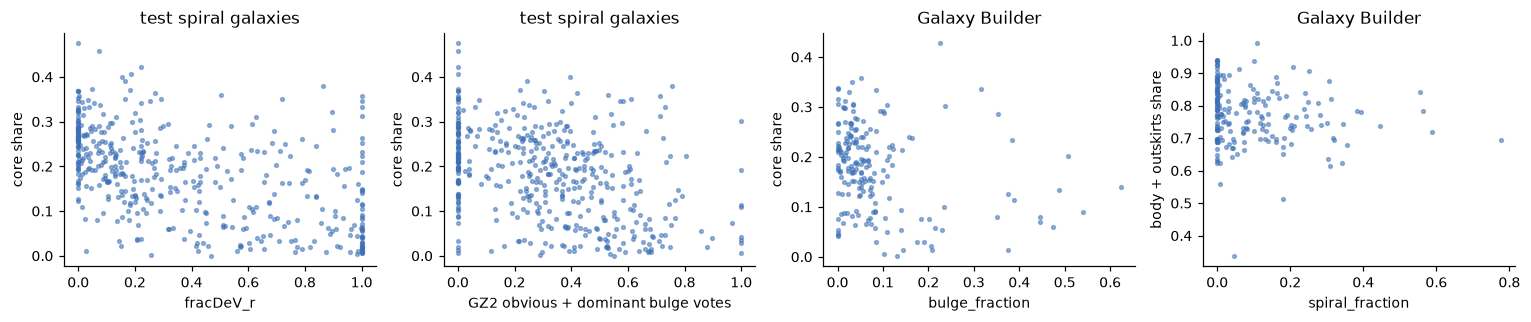

In [14]:
gb_regions = cached("region_shapley_galaxy_builder", lambda: E.region_shapley(model, data, "galaxy_builder"))
gb = E.galaxy_builder_table().merge(gb_regions, on="OBJID")
gb_share = E.shares(gb[[f"phi_region{r}" for r in range(D.N_REGIONS)]].values)

spirals = (regions.label == "spiral").values
tdf_r = df.set_index("OBJID").loc[regions.OBJID].reset_index()
checks = [
    ("test spiral galaxies", "fracDeV_r", tdf_r.fracDeV_r.values[spirals], rshare[spirals, 0], "core share"),
    ("test spiral galaxies", "GZ2 obvious + dominant bulge votes", (tdf_r.gz2_bulge_obvious + tdf_r.gz2_bulge_dominant).values[spirals], rshare[spirals, 0], "core share"),
    ("Galaxy Builder", "bulge_fraction", gb.bulge_fraction.values, gb_share[:, 0], "core share"),
    ("Galaxy Builder", "spiral_fraction", gb.spiral_fraction.values, gb_share[:, 1] + gb_share[:, 2], "body + outskirts share"),
]
rows = []
for sample, measure, xv, yv, what in checks:
    rho, p, n = E.correlate(xv, yv)
    rows.append({"galaxies": sample, "measurement": measure, "compared with": what, "spearman rho": rho, "p": p, "n": n})

fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, (sample, measure, xv, yv, what) in zip(axes, checks):
    ax.scatter(xv, yv, s=6, alpha=0.5, color=CLASS_COLORS["spiral"])
    ax.set(xlabel=measure, ylabel=what, title=sample)
fig.tight_layout()
savefig(fig, "physical_checks")

gb_pred = T.metrics(*T.predict(model, data, "galaxy_builder"))
print(f"Galaxy Builder galaxies classified as spiral: {gb_pred['acc']:.3f} (n={len(gb)})")
# signed Shapley values: positive means the region pushes toward "spiral"
signed = [
    ("test spiral galaxies", "fracDeV_r", tdf_r.fracDeV_r.values[spirals], rphi[spirals, 0], "core value"),
    ("Galaxy Builder", "bulge_fraction", gb.bulge_fraction.values, gb.phi_region0.values, "core value"),
    ("Galaxy Builder", "spiral_fraction", gb.spiral_fraction.values, (gb.phi_region1 + gb.phi_region2).values, "body + outskirts value"),
]
for sample, measure, xv, yv, what in signed:
    rho, p, n = E.correlate(xv, yv)
    rows.append({"galaxies": sample, "measurement": measure, "compared with": what, "spearman rho": rho, "p": p, "n": n})
print(f"test spiral galaxies whose core pushes toward elliptical: {(rphi[spirals, 0] < 0).mean():.1%}")
pd.DataFrame(rows).round(4)

These checks ask whether galaxies with more of a given structure get more of their explanation from where that structure is. I planned the first four rows before seeing results, and all four came out negative. Spiral galaxies with bigger central bulges get *less* of their explanation from the core, whether the size of the central bulge is measured by fracDeV_r (ρ = −0.54), by GZ2 bulge votes (ρ = −0.39) or by Galaxy Builder's fitted bulge fraction (ρ = −0.28). Galaxy Builder galaxies with more light in their spiral arms get less of their explanation from the body and outskirts (ρ = −0.21).

The signed values explain the central bulge result. The share uses the size of each value and ignores which class it points to. As the central bulge grows, the core's evidence for "spiral" shrinks (ρ = −0.63 with fracDeV_r and −0.39 with Galaxy Builder's bulge fraction), and in 13% of test spiral galaxies the core pushes toward elliptical. A central bulge has a concentrated, elliptical-like light profile and is mostly made of older, redder stars, so treating it as evidence for "elliptical" is physically sensible. The core's share shrinks because its evidence for "spiral" moves toward zero, not because the model ignores the central bulge. Part of this effect is geometric: galaxies dominated by their central bulge are more concentrated, so the core region inside R50 covers a smaller part of the galaxy.

The spiral-arm check is weaker. Galaxy Builder galaxies with more light in their arms get only slightly more evidence for "spiral" from the body and outskirts (ρ = 0.14, p = 0.049). Galaxy Builder fits are mostly disk light (median bulge fraction 0.05), so the range of these measurements is narrow, and there are only 191 galaxies.

## 5. Does band dropout change the conclusions?

The same band Shapley values for the model trained without band dropout. If the two models rank the bands the same way, the main conclusions don't depend on the band dropout choice.

In [15]:
bands_plain = cached("band_shapley_test_plain", lambda: E.band_shapley(models["plain"], data, "test"))
share_plain = E.shares(bands_plain[[f"phi_{b}" for b in C.BANDS]].values)
comp = pd.DataFrame({
    f"{lab} ({mode})": s[(b.label == lab).values].mean(0)
    for lab in C.CLASSES for mode, s, b in [("band dropout", share, bands), ("plain", share_plain, bands_plain)]
}, index=C.BANDS)
comp.round(3)

,spiral (band dropout),spiral (plain),elliptical (band dropout),elliptical (plain)
u,0.043,0.102,0.043,0.053
g,0.304,0.439,0.252,0.097
r,0.272,0.109,0.279,0.515
i,0.218,0.311,0.240,0.210
z,0.163,0.039,0.186,0.125


The plain model is just as accurate, but it divides the explanation among the bands differently. For spiral galaxies it relies on g (44%) and i (31%) and gives little to r and z. For elliptical galaxies, about half of its explanation comes from r. Both models give the u band little weight (4 to 10%), and both depend on g, r, and i. Which of those three matters most depends on how the model was trained, not on the galaxies, so I wouldn't read anything physical into the exact ranking. Band dropout spreads the explanation more evenly across bands, which is what it was meant to do.

## 6. Galaxies volunteers agreed on less

Everything above uses galaxies where more than 85% of the debiased Galaxy Zoo 1 vote went to one type. As an extra test set I added 500 galaxies of each type where the winning type got 70 to 85% of the vote, with the same 30-vote minimum, all in Galaxy Zoo 2 and none used in training. Their label is the type that won the vote. The model was not retrained.

                     accuracy    n
split    label                    
moderate elliptical     0.986  496
         spiral         0.974  495
test     elliptical     0.995  440
         spiral         0.998  439
                        accuracy  median_logodds    n
bin         label                                    
(0.7, 0.75] elliptical     0.957           8.540  138
            spiral         0.954          10.195  151
(0.75, 0.8] elliptical     1.000          10.355  156
            spiral         0.983          10.899  173
(0.8, 0.85] elliptical     0.995          11.237  202
            spiral         0.982          11.579  171
(0.85, 0.9] elliptical     0.989          12.305  175
            spiral         0.989          13.417   93
(0.9, 0.95] elliptical     1.000          12.359  159
            spiral         1.000          13.802  127
(0.95, 1.0] elliptical     1.000          13.303  106
            spiral         1.000          15.249  219

medians for all moderate galaxies

,class,spearman rho (vote vs model probability),p,n
0,spiral,0.4331,0.0,934
1,elliptical,0.3522,0.0,936


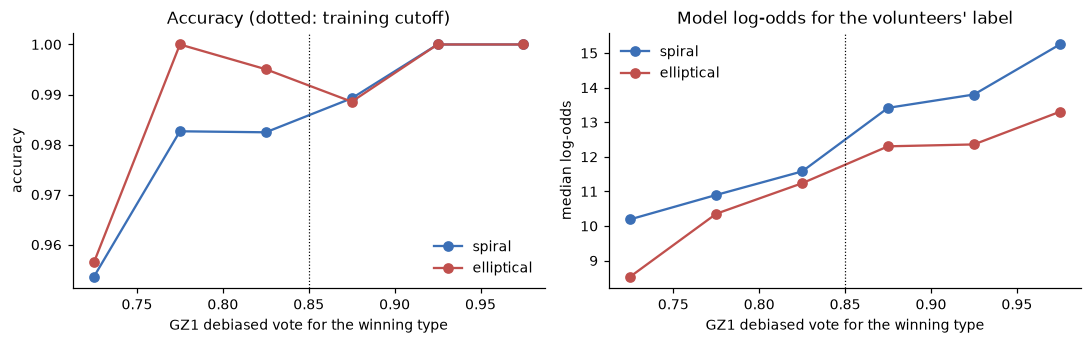

In [16]:
def scored(split):
    p, y = T.predict(model, data, split)
    d = data.df.iloc[E.split_index(data, split)].reset_index(drop=True)
    d["agreement"] = np.where(d.label == "spiral", d.P_CS_DEBIASED, d.P_EL_DEBIASED)
    d["p_label"] = np.where(y == 1, p, 1 - p)
    d["logodds_label"] = np.log(d.p_label + 1e-12) - np.log(1 - d.p_label + 1e-12)
    d["correct"] = (p > 0.5) == y
    return d

scores = pd.concat([scored("test"), scored("moderate")], ignore_index=True)
print(scores.groupby(["split", "label"]).correct.agg(["mean", "size"]).round(3).rename(columns={"mean": "accuracy", "size": "n"}))

edges = [0.70, 0.75, 0.80, 0.85, 0.90, 0.95, 1.0001]
scores["bin"] = pd.cut(scores.agreement, edges, right=True)
by_bin = scores.groupby(["bin", "label"], observed=True).agg(accuracy=("correct", "mean"), median_logodds=("logodds_label", "median"), n=("correct", "size"))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
centers = (np.array(edges[:-1]) + np.minimum(edges[1:], 1)) / 2
for lab in C.CLASSES:
    b = by_bin.xs(lab, level="label").reindex(scores.bin.cat.categories)
    axes[0].plot(centers, b.accuracy, "o-", color=CLASS_COLORS[lab], label=lab)
    axes[1].plot(centers, b.median_logodds, "o-", color=CLASS_COLORS[lab], label=lab)
for ax in axes:
    ax.axvline(0.85, c="k", ls=":", lw=0.8)
    ax.set_xlabel("GZ1 debiased vote for the winning type")
    ax.legend(frameon=False)
axes[0].set(ylabel="accuracy", title="Accuracy (dotted: training cutoff)")
axes[1].set(ylabel="median log-odds", title="Model log-odds for the volunteers' label")
fig.tight_layout()
savefig(fig, "agreement")

rows = []
for lab in C.CLASSES:
    m = (scores.label == lab).values
    rho, p, n = E.correlate(scores.agreement.values[m], scores.p_label.values[m])
    rows.append({"class": lab, "spearman rho (vote vs model probability)": rho, "p": p, "n": n})
print(by_bin.round(3))

moderate = scores[scores.split == "moderate"]
print("\nmedians for all moderate galaxies and for the ones the model gets wrong")
cols = ["agreement", "u_minus_r", "fracDeV_r", "gz2_features"]
print(pd.concat({"all": moderate.groupby("label")[cols].median(), "wrong": moderate[~moderate.correct].groupby("label")[cols].median(),}, axis=1).round(3))
print("wrong:", (~moderate.correct).groupby(moderate.label).sum().to_dict())
print("moderate elliptical galaxies that GZ2 volunteers saw as having features or a disk (> 0.5):", f"{(moderate[moderate.label == 'elliptical'].gz2_features > 0.5).mean():.0%}")
pd.DataFrame(rows).round(4)


In [17]:
mod_bands = cached("band_shapley_moderate", lambda: E.band_shapley(model, data, "moderate"))
mod_regions = cached("region_shapley_moderate", lambda: E.region_shapley(model, data, "moderate"))
mod_share = E.shares(mod_bands[[f"phi_{b}" for b in C.BANDS]].values)
mod_rphi = mod_regions[[f"phi_region{r}" for r in range(D.N_REGIONS)]].values

# rows are grouped by the model's prediction, since the values explain the predicted class
table = {}
for lab in C.CLASSES:
    t, m = (bands.pred == lab).values, (mod_bands.pred == lab).values
    table[f"band share, predicted {lab} (test)"] = pd.Series(share[t].mean(0), C.BANDS)
    table[f"band share, predicted {lab} (moderate)"] = pd.Series(mod_share[m].mean(0), C.BANDS)
print(pd.DataFrame(table).round(3))

table = {}
for lab in C.CLASSES:
    t, m = (regions.pred == lab).values, (mod_regions.pred == lab).values
    table[f"predicted {lab} (test)"] = pd.Series(rphi[t].mean(0), REGION_SHORT)
    table[f"predicted {lab} (moderate)"] = pd.Series(mod_rphi[m].mean(0), REGION_SHORT)
table = pd.DataFrame(table)
table.loc["total"] = table.sum()
print("\nmean region Shapley values (log-odds toward the predicted class)")
table.round(3)


   band share, predicted spiral (test)  \
u                                0.043   
g                                0.305   
r                                0.273   
i                                0.217   
z                                0.162   

   band share, predicted spiral (moderate)  \
u                                    0.073   
g                                    0.297   
r                                    0.258   
i                                    0.203   
z                                    0.168   

   band share, predicted elliptical (test)  \
u                                    0.043   
g                                    0.251   
r                                    0.278   
i                                    0.241   
z                                    0.186   

   band share, predicted elliptical (moderate)  
u                                        0.064  
g                                        0.239  
r                                        0.261

,predicted spiral (test),predicted spiral (moderate),predicted elliptical (test),predicted elliptical (moderate)
core,2.331,1.210,6.566,5.692
body,9.223,8.269,0.357,-0.641
outskirts,2.352,1.338,3.393,3.080
background,0.655,0.301,1.582,1.439
total,14.561,11.118,11.897,9.571


After the same edge-of-frame cut as the main sample, 991 galaxies remain (496 elliptical and 495 spiral galaxies). The model gets 98.0% of them right (98.6% of elliptical galaxies and 97.4% of spiral galaxies), against 99.7% on the main test set. Almost all of the drop is in the least certain group: for galaxies where 70 to 75% of volunteers agreed, accuracy is about 95.5%. Above 75% it is 98% or higher.

The more useful result is how the model's log-odds change. The model was trained only on galaxies above 85% agreement, with plain spiral/elliptical labels, and never saw a vote fraction. Even so, its log-odds for the volunteers' label fall steadily as volunteer agreement falls. For spiral galaxies the median log-odds drops from 15.2 at 95 to 100% agreement to 10.2 at 70 to 75%. For elliptical galaxies it drops from 13.3 to 8.5. Across both test sets, the Spearman correlation between the vote fraction and the model's probability for the volunteers' label is 0.43 for spiral galaxies and 0.35 for elliptical galaxies. The galaxies volunteers found harder to call are also the ones the model is less sure about. Even the lowest median log-odds (8.5) means a probability above 0.999, though, so the model is far more confident than the volunteers. Its probabilities shouldn't be read as vote fractions, and I didn't measure its calibration directly.

The 20 mistakes follow a pattern. The 13 spiral galaxies the model calls elliptical are red (median u − r of 2.83, about the same as a typical elliptical) and have bulge-like light profiles (median fracDeV_r of 1.00), but Galaxy Zoo 2 volunteers still saw features or a disk in them (median 0.94). These are probably early-type disk galaxies with a large central bulge and little star formation, the galaxies that sit between the two classes. The 7 elliptical galaxies called spiral are bluer than other moderate elliptical galaxies (median u − r of 2.54 against 2.79). The labels in this set are also less certain to begin with: in Galaxy Zoo 2, more than half of the volunteers saw features or a disk in 24% of the moderate elliptical galaxies.

The explanations look much like those for the main test set. The share of each band barely changes, apart from u, which goes up a little (from 4% to 6 or 7%). The regions follow the same pattern, but the model has less evidence overall: 11.1 log-odds for predicted spiral galaxies against 14.6, and 9.6 for predicted elliptical galaxies against 11.9. For spiral galaxies, most of the drop is in the core and outskirts, and the disk (body) region stays almost as strong. For elliptical galaxies, the body region now points slightly toward "spiral" on average (−0.64), which fits these galaxies having some disk-like light between R50 and R90. Here the values are grouped by the model's prediction rather than the label, since they explain the predicted class.

## 7. Do the Shapley values reflect the trained model?

Project 1 showed that an explanation can look reasonable without depending on what the model learned. Two checks test that here.

**Model randomization.** If the band and region values came mostly from the images themselves (for example, the core always being brightest), a model with random weights would get similar values. I re-initialized every weight of the main model three times and recomputed the exact Shapley values on the test set, explaining the same class the trained model predicted. For each galaxy I compare the trained and random values with a Spearman correlation. As a reference, I also compare the two trained models (band dropout and plain), on the galaxies where they predict the same class.

**Removal order.** Shapley values average a player's effect over every combination of the others. A different question is whether removing the players one at a time, largest value first, lowers the model's log-odds faster than removing them in a random order or smallest first. This uses the log-odds already computed for every combination, so it needs no new model runs.

In [18]:
target = torch.tensor([C.CLASSES.index(p) for p in bands.pred], device=device)
band_cols = [f"phi_{b}" for b in C.BANDS]
region_cols = [f"phi_region{r}" for r in range(D.N_REGIONS)]

regions_plain = cached("region_shapley_test_plain", lambda: E.region_shapley(models["plain"], data, "test"))
same = (bands.pred.values == bands_plain.pred.values) & (regions.pred.values == regions_plain.pred.values)
comparisons = {"trained (band dropout) vs trained (plain)": (bands_plain[same], regions_plain[same], same)}
for seed in range(3):
    rm = E.randomized_copy(model, seed)
    rb = cached(f"band_shapley_test_random{seed}", lambda: E.band_shapley(rm, data, "test", target))
    rr = cached(f"region_shapley_test_random{seed}", lambda: E.region_shapley(rm, data, "test", target))
    comparisons[f"trained vs random weights (seed {seed})"] = (rb, rr, np.ones(len(bands), bool))

rows = []
for name, (b, r, m) in comparisons.items():
    rho_b = E.per_galaxy_spearman(bands[band_cols].values[m], b[band_cols].values)
    rho_r = E.per_galaxy_spearman(regions[region_cols].values[m], r[region_cols].values)
    rows.append({"comparison": name, "n": int(m.sum()),
                 "bands: median rho": np.nanmedian(rho_b), "regions: median rho": np.nanmedian(rho_r)})
print(pd.DataFrame(rows).round(3).to_string(index=False))

# does a random model also put most of the attribution in the same places?
shares = {"trained": (E.shares(bands[band_cols].values).mean(0), E.shares(regions[region_cols].values).mean(0))}
for seed in range(3):
    rb, rr = comparisons[f"trained vs random weights (seed {seed})"][:2]
    shares[f"random {seed}"] = (E.shares(rb[band_cols].values).mean(0), E.shares(rr[region_cols].values).mean(0))
print("\nmean share of |Shapley| by band")
print(pd.DataFrame({k: v[0] for k, v in shares.items()}, index=C.BANDS).round(3))
print("\nmean share of |Shapley| by region")
pd.DataFrame({k: v[1] for k, v in shares.items()}, index=REGION_SHORT).round(3)


                               comparison   n  bands: median rho  regions: median rho
trained (band dropout) vs trained (plain) 878                0.3                  0.8
       trained vs random weights (seed 0) 879               -0.1                  0.2
       trained vs random weights (seed 1) 879                0.0                  0.4
       trained vs random weights (seed 2) 879                0.0                  0.4

mean share of |Shapley| by band
   trained  random 0  random 1  random 2
u    0.043     0.174     0.051     0.249
g    0.278     0.154     0.148     0.074
r    0.276     0.264     0.470     0.485
i    0.229     0.213     0.253     0.052
z    0.174     0.195     0.077     0.140

mean share of |Shapley| by region


,trained,random 0,random 1,random 2
core,0.346,0.153,0.125,0.121
body,0.357,0.190,0.268,0.253
outskirts,0.206,0.204,0.173,0.271
background,0.091,0.453,0.434,0.355


fraction of galaxies where removing the largest values first lowers the log-odds more than a random order:
players
bands      0.995
regions    0.978

mean log-odds after removing k bands
removed             0      1      2      3     4    5
order                                                
largest first   13.23  11.55   9.65   6.34  0.07 -0.0
random          13.23  12.50  11.48   9.61  5.85 -0.0
smallest first  13.23  13.31  12.78  11.72  9.16 -0.0

mean log-odds after removing k regions
removed             0     1     2     3    4
order                                       
largest first   13.23  2.95 -5.62 -5.23 -0.0
random          13.23  6.10  1.91  0.08 -0.0
smallest first  13.23  7.04  4.20  6.08 -0.0


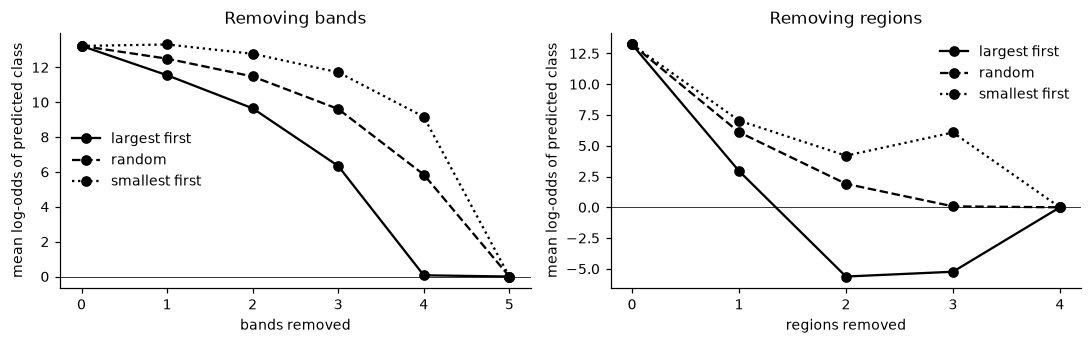

In [19]:
curves = pd.concat([E.deletion_curves(bands, len(C.BANDS)).assign(players="bands"),
                    E.deletion_curves(regions, D.N_REGIONS).assign(players="regions")])
mean_curves = curves.groupby(["players", "order", "removed"]).log_odds.mean()

ORDER_STYLE = {"largest first": "-", "random": "--", "smallest first": ":"}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, players in zip(axes, ["bands", "regions"]):
    for order, ls in ORDER_STYLE.items():
        c = mean_curves[players][order]
        ax.plot(c.index, c.values, ls, marker="o", color="k", label=order)
    ax.axhline(0, c="k", lw=0.5)
    ax.set_xticks(range(int(mean_curves[players].index.get_level_values("removed").max()) + 1))
    ax.set(title=f"Removing {players}", xlabel=f"{players} removed", ylabel="mean log-odds of predicted class")
    ax.legend(frameon=False)
fig.tight_layout()
savefig(fig, "deletion")

# per galaxy: is the largest-first curve below the random one on average (area over the steps in between)?
inner = curves[(curves.removed > 0) & (curves.removed < curves.groupby("players").removed.transform("max"))]
area = inner.groupby(["players", "OBJID", "order"]).log_odds.mean().unstack("order")
print("fraction of galaxies where removing the largest values first lowers the log-odds more than a random order:")
print((area["largest first"] < area["random"]).groupby("players").mean().round(3).to_string())
for players in ["bands", "regions"]:
    print(f"\nmean log-odds after removing k {players}")
    print(mean_curves[players].unstack("removed").round(2))


**Model randomization.** The explanations depend on the trained weights. For regions, the two trained models give similar values (median per-galaxy Spearman ρ of 0.8), while models with random weights match the trained one much less (0.2 to 0.4). The random models also spread their attribution differently: they put 35 to 45% of it in the background, while the trained model puts 9% there and about a third each in the core and the body. So the region pattern in section 2 was learned, not a product of where the light is. The random models' outputs barely change with the input (their Shapley values are around 10⁻⁴ log-odds), so the comparison rests on the ranking of the values, which Spearman correlation measures regardless of scale.

The bands behave differently. Random models disagree with the trained one (median ρ around 0), but the two trained models only partly agree with each other (0.3). This fits section 5: the bands carry overlapping information, so how the credit is split among g, r, and i depends on the particular model. The band explanations reflect the model they come from, but the exact band ranking shouldn't be read as a property of the galaxies.

**Removal order.** Removing the players with the largest Shapley values first lowers the log-odds faster than a random order for 99.5% of test galaxies with bands and 97.8% with regions. On average, removing the single largest region cuts the log-odds from 13.2 to 3.0, against 6.1 for a random region. The Shapley values do point to the parts the prediction depends on most.

The region curves also show a limitation. They aren't monotonic. After the two largest regions are removed, the average log-odds is −5.6, meaning the model now leans toward the other class, and removing a third region moves it back up slightly. Removing the smallest region first still lowers the log-odds by about 6. Blanking a region doesn't just take away evidence. It creates an image with a hole or a ring, unlike any real galaxy, and the model reacts to that shape. This is the zeroing problem from the limitations in action, and it's a reason to trust the overall region pattern more than any single number.

## Summary

- The CNN separates confident spiral and elliptical galaxies almost perfectly (99.7% on the test set and 98.4% on held-out Galaxy Builder spiral galaxies). It does nearly as well from a single g or r image, so it doesn't need color.
- A logistic regression on SDSS colors and light-profile measurements gets 91.9%, so both color and structure carry real information. The CNN's extra 8 points come largely from spiral galaxies whose catalog values look elliptical-like. For those, the model relies on the disk region and overrides a core that points toward elliptical.
- Across the five bands, the model's evidence comes mostly from g, r, and i. Spiral galaxies lean a little more on g and elliptical galaxies a little more on the redder bands, in the direction expected from their colors, but the effect is small. The faint u band contributes about 4%.
- Spatially, the spiral evidence comes from between R50 and R90, where most of a disk's light usually is, and the elliptical evidence comes from the core and outskirts. This is the clearest sign that the model uses galaxy structure.
- TCAV with Galaxy Zoo 2 concepts agrees with volunteer morphology for arms, bars, and round, smooth shapes. The edge-on result shows these scores are not just the class labels in another form.
- In spiral galaxies with bigger central bulges, the core gives less evidence for "spiral" and sometimes points toward elliptical. This holds for SDSS profile fits, GZ2 votes, and Galaxy Builder bulge fractions, and fits the central bulge's elliptical-like structure. The link between spiral-arm light and disk evidence is weak.
- On 991 galaxies with only 70 to 85% volunteer agreement, which were not used in training, the model gets 98.0% right. Its log-odds for the volunteers' label drop as agreement drops, even though it never saw vote fractions. Most of its mistakes are red disk galaxies with large central bulges that it calls elliptical.
- The region explanations pass a model-randomization check, and removing the highest-valued parts first hurts the prediction most for 98–99% of galaxies. Band explanations also depend on the trained weights, but the two trained models split the credit among g, r, and i differently.
- The exact ranking of the bands changes between the two models, so only the broad pattern should be trusted.

## Limitations

- **Easy galaxies.** The model was trained only on galaxies where more than 85% of GZ1 volunteers agreed. The moderate-agreement set goes down to 70%, but galaxies below that, including many lenticulars, disks with large central bulges, and mergers, are still left out. The moderate set is also evaluated with the winning vote as its label, which is less reliable there.
- **Labels are votes.** Galaxy Zoo labels are volunteer consensus with corrections for redshift bias, not a ground truth. GZ1 and GZ2 sometimes disagree, as the prominent-bulge concept set shows.
- **Removing a band or region means zeroing it.** After sky subtraction, zero means "no light", which is a natural baseline, but a galaxy with a missing band or a blank ring is still unlike anything real. Band dropout trains the main model on missing bands, but nothing does the same for missing regions. The uneven removal curves in section 7 show the model reacting to these artificial shapes.
- **Circular regions.** The regions are circles based on Petrosian radii. Inclined disks look elliptical on the sky, so a circular region mixes parts of the disk with background, and the core region is smaller for more concentrated galaxies.
- **TCAV.** Most concept sets are dominated by one class, and I used one layer (the output of the third convolution block). The random baseline also differs between the two target classes.
- **KernelSHAP** values are estimates from 2,000 samples on 200 galaxies, and they don't add up to the exact region values.
- **Galaxy Builder** only has 191 usable galaxies, gives fractions rather than positions, and its central bulges are mostly small.
- **One training run per model.** The hyperparameters come from project 1, which used a different input format, and each model was trained with a single seed. The plain-vs-dropout comparison shows that band rankings can shift between runs.

## Data

Images: Sloan Digital Sky Survey, DR17 calibrated frames. Labels: Galaxy Zoo 1 (Lintott et al. 2008, 2011), Galaxy Zoo 2 (Willett et al. 2013; debiased table from Hart et al. 2016) and Galaxy Builder (Lingard et al. 2020), as requested on the Galaxy Zoo data page.